# Project 3 – Part 2: Two strains with waning immunity (ODE versus SSA)

Training Workshop in Mathematical Biology 2026, Thursday projects.

This notebook answers Section 2 of the project sheet, using **the system of equations (2.1) to (2.5) exactly as printed in the sheet**:

$$\frac{dS}{dt}=\mu(1-S)-\beta_1SI_1-\beta_2SI_2+\omega_1R_1+\omega_2R_2 \qquad (2.1)$$
$$\frac{dI_1}{dt}=\beta_1SI_1-(\gamma_1+\mu)I_1 \qquad (2.2)$$
$$\frac{dI_2}{dt}=\beta_2SI_2-(\gamma_2+\mu)I_2 \qquad (2.3)$$
$$\frac{dR_1}{dt}=\gamma_1I_1-(\omega_1+\mu)R_1 \qquad (2.4)$$
$$\frac{dR_2}{dt}=\gamma_2I_2-(\omega_2+\mu)R_2 \qquad (2.5)$$

| Step | Sheet item | What we do |
|---|---|---|
| A | Investigation 1 | Cartoon network |
| B | Investigation 2 | Eliminate $S$ and get a four dimensional system |
| C | Investigation 3 | ODE, Gillespie SSA, side by side plot |
| D | Investigation 4 | $\mathcal R_0$, coexistence or cycles, stochastic extinction |

## Remarks on the sheet

1. **Typo:** the text says transmission rates "$\beta_1$ and $\beta_1$". It must be $\beta_1$ and $\beta_2$.
2. **The code given in the sheet contains two extra terms** ($\beta_1R_2I_1$ and $\beta_2R_1I_2$) that are **not** in equations (2.2) to (2.5). We follow the equations, so these terms are not used anywhere in this notebook.
3. **Convention for $N$:** the ODE is written in **proportions** ($S+I_1+I_2+R_1+R_2=1$), so the SSA uses the propensity $\beta SI/N$ for infections. This is the same model in counts.

In the SSA, births ($\mu N$) and deaths ($\mu X$) are separate random events, so the total population is only conserved on average and fluctuates around $N$. The ODE conserves it exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sympy as sp
import time
from scipy.integrate import solve_ivp

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
C = dict(S="#4C6A86", I1="#BF4E2C", R1="#228066", I2="#7C4A9C", R2="#B3802F")

# Parameters of the project sheet (time unit: years)
N = 10_000
mu = 0.02
beta1, gamma1, omega1 = 120.0, 52.0, 0.2     # strain 1: 1 week infection, 5 years immunity
beta2, gamma2, omega2 = 100.0, 26.0, 0.5     # strain 2: 2 weeks infection, 2 years immunity
t_max = 50
pars = (mu, beta1, gamma1, omega1, beta2, gamma2, omega2)

## A. Investigation 1: cartoon network

Five classes: $S$ (naive or waned), $I_1$, $I_2$, $R_1$, $R_2$. Each strain has its own loop $S\to I_i\to R_i\to S$: infection, recovery, waning of immunity. Newborns enter $S$ at rate $\mu N$ and every class loses individuals by death at rate $\mu$. The two strains interact only through $S$: they compete for the same susceptible people. Someone in $R_1$ or $R_2$ cannot be infected until immunity wanes back to $S$.

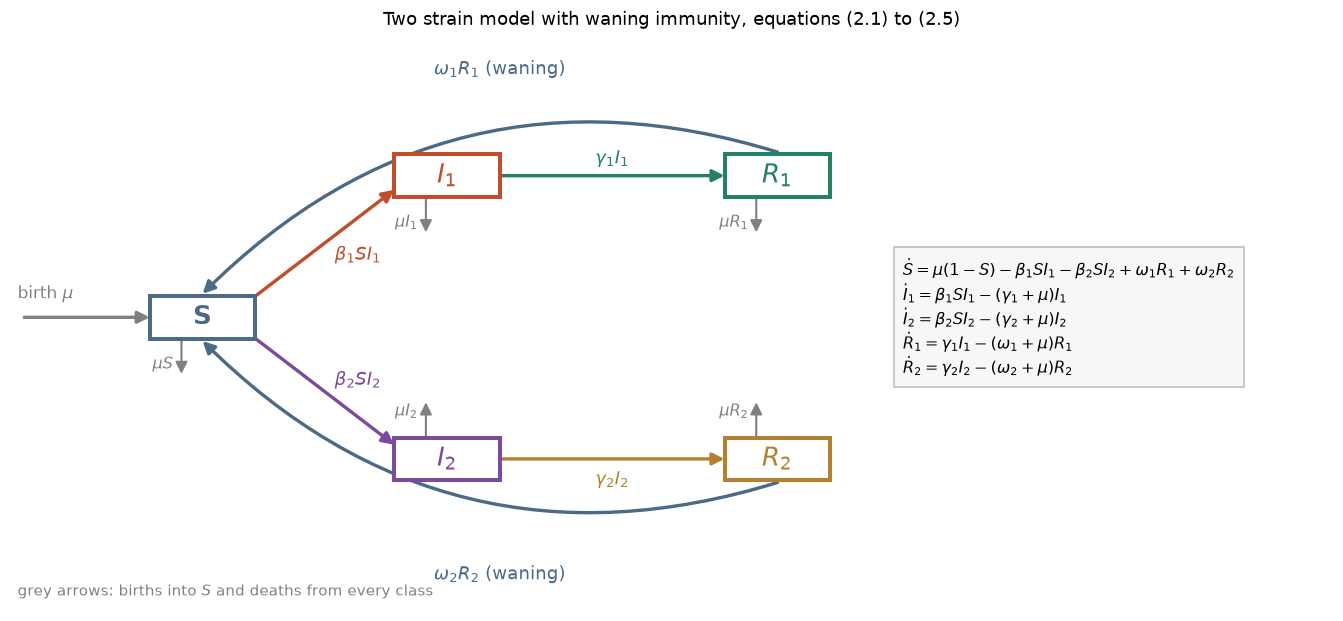

In [2]:
fig, ax = plt.subplots(figsize=(15.5, 6.8)); ax.axis("off"); ax.set_xlim(-1.4, 18.6); ax.set_ylim(-1.2, 11.0)
pos = dict(S=(1.5, 5.0), I1=(5.2, 8.0), R1=(10.2, 8.0), I2=(5.2, 2.0), R2=(10.2, 2.0))
name = dict(S="S", I1="$I_1$", R1="$R_1$", I2="$I_2$", R2="$R_2$")
HW, HH = 0.8, 0.45
for k, (x, y) in pos.items():
    ax.add_patch(plt.Rectangle((x-HW, y-HH), 2*HW, 2*HH, fc="white", ec=C[k], lw=2.6, zorder=5))
    ax.text(x, y, name[k], ha="center", va="center", fontsize=17, fontweight="bold", color=C[k], zorder=6)
def arrow(p, q, color, rad=0.0, ls="-", lw=2.2):
    ax.annotate("", xy=q, xytext=p, zorder=3,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, ls=ls, mutation_scale=16,
                                connectionstyle=f"arc3,rad={rad}", shrinkA=0, shrinkB=0))
# infection and recovery
arrow((2.3, 5.45), (4.4, 7.7), C["I1"]);   ax.text(3.5, 6.2, r"$\beta_1 S I_1$", color=C["I1"], fontsize=12)
arrow((6.0, 8.0), (9.4, 8.0), C["R1"]);    ax.text(7.7, 8.25, r"$\gamma_1 I_1$", color=C["R1"], fontsize=12, ha="center")
arrow((2.3, 4.55), (4.4, 2.3), C["I2"]);   ax.text(3.5, 3.55, r"$\beta_2 S I_2$", color=C["I2"], fontsize=12)
arrow((6.0, 2.0), (9.4, 2.0), C["R2"]);    ax.text(7.7, 1.45, r"$\gamma_2 I_2$", color=C["R2"], fontsize=12, ha="center")
# waning back to S
arrow((10.2, 8.5), (1.5, 5.5), C["S"], rad=0.30);   ax.text(6.0, 10.15, r"$\omega_1 R_1$ (waning)", color=C["S"], fontsize=12, ha="center")
arrow((10.2, 1.5), (1.5, 4.5), C["S"], rad=-0.30);  ax.text(6.0, -0.55, r"$\omega_2 R_2$ (waning)", color=C["S"], fontsize=12, ha="center")
# births and deaths
arrow((-1.2, 5.0), (0.7, 5.0), "gray");  ax.text(-1.3, 5.4, r"birth $\mu$", color="gray", fontsize=11)
death = dict(S=r"$\mu S$", I1=r"$\mu I_1$", R1=r"$\mu R_1$", I2=r"$\mu I_2$", R2=r"$\mu R_2$")
for k in pos:
    # death arrows point towards the middle of the figure, away from the waning arcs
    x, y = pos[k]; sgn = 1 if k in ("I2", "R2") else -1
    y0 = y + sgn*HH; arrow((x - HW*0.4, y0), (x - HW*0.4, y0 + sgn*0.75), "gray", lw=1.4)
    ax.text(x - HW*0.4 - 0.12, y0 + sgn*0.55, death[k], color="gray", fontsize=10.5, ha="right", va="center")
ax.text(-1.3, -0.9, "grey arrows: births into $S$ and deaths from every class", color="gray", fontsize=10, ha="left")
ax.text(12.1, 5.0,
        r"$\dot S=\mu(1-S)-\beta_1SI_1-\beta_2SI_2+\omega_1R_1+\omega_2R_2$" "\n"
        r"$\dot I_1=\beta_1SI_1-(\gamma_1+\mu)I_1$" "\n"
        r"$\dot I_2=\beta_2SI_2-(\gamma_2+\mu)I_2$" "\n"
        r"$\dot R_1=\gamma_1I_1-(\omega_1+\mu)R_1$" "\n"
        r"$\dot R_2=\gamma_2I_2-(\omega_2+\mu)R_2$",
        fontsize=10.5, ha="left", va="center", bbox=dict(fc="#f7f7f7", ec="#bbbbbb", pad=6))
ax.set_title("Two strain model with waning immunity, equations (2.1) to (2.5)", fontsize=12)
plt.show()

### The events of the SSA, their state change vectors and propensities (state $[S,I_1,I_2,R_1,R_2]$, in counts)

Each term of the ODE becomes one random event. In counts, a term $\beta SI$ of the proportions model becomes the propensity $\beta S I/N$.

| # | Event | Change | Propensity | ODE term |
|---|---|---|---|---|
| 0 | Birth into $S$ | $[+1,0,0,0,0]$ | $\mu N$ | $\mu$ in (2.1) |
| 1 to 5 | Death of $S,I_1,I_2,R_1,R_2$ | $-1$ in that class | $\mu S,\ \mu I_1,\ \mu I_2,\ \mu R_1,\ \mu R_2$ | the $-\mu(\cdot)$ terms |
| 6 | $S\to I_1$ | $[-1,+1,0,0,0]$ | $\beta_1SI_1/N$ | $\beta_1SI_1$ |
| 7 | $S\to I_2$ | $[-1,0,+1,0,0]$ | $\beta_2SI_2/N$ | $\beta_2SI_2$ |
| 8 | $I_1\to R_1$ | $[0,-1,0,+1,0]$ | $\gamma_1I_1$ | $\gamma_1I_1$ |
| 9 | $I_2\to R_2$ | $[0,0,-1,0,+1]$ | $\gamma_2I_2$ | $\gamma_2I_2$ |
| 10 | $R_1\to S$ (waning) | $[+1,0,0,-1,0]$ | $\omega_1R_1$ | $\omega_1R_1$ |
| 11 | $R_2\to S$ (waning) | $[+1,0,0,0,-1]$ | $\omega_2R_2$ | $\omega_2R_2$ |

There are 12 events, one for each term of equations (2.1) to (2.5).

## B. Investigation 2: reduction to a four dimensional system

**Step 1: the sum of the five fractions does not change.** Add equations (2.1) to (2.5):

$$
\begin{aligned}
\frac{d}{dt}(S+I_1+I_2+R_1+R_2)
=\;&\mu-\mu S-\beta_1SI_1-\beta_2SI_2+\omega_1R_1+\omega_2R_2\\
&+\beta_1SI_1-\gamma_1I_1-\mu I_1\\
&+\beta_2SI_2-\gamma_2I_2-\mu I_2\\
&+\gamma_1I_1-\omega_1R_1-\mu R_1\\
&+\gamma_2I_2-\omega_2R_2-\mu R_2
\end{aligned}
$$

Every transfer term appears once with $+$ and once with $-$:

$$
\begin{aligned}
=\;&\mu
+\underbrace{(-\beta_1SI_1+\beta_1SI_1)}_{0}
+\underbrace{(-\beta_2SI_2+\beta_2SI_2)}_{0}
+\underbrace{(-\gamma_1I_1+\gamma_1I_1)}_{0}
+\underbrace{(-\gamma_2I_2+\gamma_2I_2)}_{0}\\
&+\underbrace{(\omega_1R_1-\omega_1R_1)}_{0}
+\underbrace{(\omega_2R_2-\omega_2R_2)}_{0}
-\mu S-\mu I_1-\mu I_2-\mu R_1-\mu R_2
\end{aligned}
$$

$$
\frac{d}{dt}(S+I_1+I_2+R_1+R_2)=\mu\big[1-(S+I_1+I_2+R_1+R_2)\big].
$$

At $t=0$ the fractions add up to 1 ($0.99+0.005+0.005+0+0=1$), so the right hand side is $\mu(1-1)=0$ and the sum never changes:

$$
S+I_1+I_2+R_1+R_2=1\ \text{ for all } t
\qquad\Longrightarrow\qquad
\boxed{S=1-I_1-I_2-R_1-R_2}
$$

**Step 2: substitute $S$ in (2.2) and (2.3).**

$$\frac{dI_1}{dt}=\beta_1SI_1-(\gamma_1+\mu)I_1=\beta_1\big(1-I_1-I_2-R_1-R_2\big)I_1-(\gamma_1+\mu)I_1$$
$$\frac{dI_2}{dt}=\beta_2SI_2-(\gamma_2+\mu)I_2=\beta_2\big(1-I_1-I_2-R_1-R_2\big)I_2-(\gamma_2+\mu)I_2$$

**Step 3.** Equations (2.4) and (2.5) contain no $S$, so they are unchanged. Equation (2.1) is no longer needed, because $S$ is known from the other four.

**Result:**
$$\boxed{\begin{aligned}
\frac{dI_1}{dt}&=\beta_1\,(1-I_1-I_2-R_1-R_2)\,I_1-(\gamma_1+\mu)I_1\\
\frac{dI_2}{dt}&=\beta_2\,(1-I_1-I_2-R_1-R_2)\,I_2-(\gamma_2+\mu)I_2\\
\frac{dR_1}{dt}&=\gamma_1I_1-(\omega_1+\mu)R_1\\
\frac{dR_2}{dt}&=\gamma_2I_2-(\omega_2+\mu)R_2
\end{aligned}}$$

Both strains use the same pool of susceptibles $S=1-I_1-I_2-R_1-R_2$: this is why they compete.

The cell below checks the three steps symbolically.

In [3]:
S, I1, I2, R1, R2 = sp.symbols("S I1 I2 R1 R2")
m, b1, g1, w1, b2, g2, w2 = sp.symbols("mu beta1 gamma1 omega1 beta2 gamma2 omega2", positive=True)

# equations (2.1) to (2.5)
dS  = m*(1 - S) - b1*S*I1 - b2*S*I2 + w1*R1 + w2*R2
dI1 = b1*S*I1 - (g1 + m)*I1
dI2 = b2*S*I2 - (g2 + m)*I2
dR1 = g1*I1 - (w1 + m)*R1
dR2 = g2*I2 - (w2 + m)*R2

# 1) sum of the derivatives = mu*(1 - sum of the fractions)
print("sum of derivatives - mu*(1 - S-I1-I2-R1-R2) =", sp.simplify(dS + dI1 + dI2 + dR1 + dR2 - m*(1 - (S+I1+I2+R1+R2))))

# 2) substitute S = 1 - I1 - I2 - R1 - R2 and compare with the boxed four dimensional system
sub = {S: 1 - I1 - I2 - R1 - R2}
red = [sp.expand(e.subs(sub)) for e in (dI1, dI2, dR1, dR2)]
boxed = [b1*(1-I1-I2-R1-R2)*I1 - (g1+m)*I1,
         b2*(1-I1-I2-R1-R2)*I2 - (g2+m)*I2,
         g1*I1 - (w1+m)*R1,
         g2*I2 - (w2+m)*R2]
print("difference with the boxed system:", [sp.simplify(a - b) for a, b in zip(red, boxed)])

# 3) equation (2.1) is redundant: on S = 1 - I1 - I2 - R1 - R2, dS/dt = -(dI1 + dI2 + dR1 + dR2)
print("dS/dt + (dI1+dI2+dR1+dR2) with S substituted:", sp.simplify((dS + dI1 + dI2 + dR1 + dR2).subs(sub)))

sum of derivatives - mu*(1 - S-I1-I2-R1-R2) = 0
difference with the boxed system: [0, 0, 0, 0]
dS/dt + (dI1+dI2+dR1+dR2) with S substituted: 0


## C. Investigation 3: ODE, Gillespie SSA, side by side

### ODE (proportions)
`waning_two_strain_sir` is the sheet's function, written with equations (2.1) to (2.5).

In [4]:
def waning_two_strain_sir(t, y, mu, beta1, gamma1, omega1, beta2, gamma2, omega2):
    """Equations (2.1) to (2.5) of the sheet."""
    S, I1, I2, R1, R2 = y
    dS_dt  = mu*(1 - S) - beta1*S*I1 - beta2*S*I2 + omega1*R1 + omega2*R2
    dI1_dt = beta1*S*I1 - (gamma1 + mu)*I1
    dI2_dt = beta2*S*I2 - (gamma2 + mu)*I2
    dR1_dt = gamma1*I1 - (omega1 + mu)*R1
    dR2_dt = gamma2*I2 - (omega2 + mu)*R2
    return [dS_dt, dI1_dt, dI2_dt, dR1_dt, dR2_dt]

def solve_model(rhs, y0, t_end, n=5001, atol=1e-30):
    # LSODA with tight tolerances: rates are large (beta = 120 per year) and we want to follow very small values
    return solve_ivp(rhs, (0, t_end), y0, args=pars, t_eval=np.linspace(0, t_end, n),
                     method="LSODA", rtol=1e-10, atol=atol)

y0_ode = [0.99, 0.005, 0.005, 0.0, 0.0]
y0_stoch = [int(round(p * N)) for p in y0_ode]
sol_ode = solve_model(waning_two_strain_sir, y0_ode, t_max)
print("initial counts for the SSA:", y0_stoch, "sum =", sum(y0_stoch))
print("ODE: sum of the fractions at the end =", sol_ode.y[:, -1].sum())
print("ODE at t = 50 years [S, I1, I2, R1, R2] =", np.array2string(sol_ode.y[:, -1], precision=5))

initial counts for the SSA: [9900, 50, 50, 0, 0] sum = 10000
ODE: sum of the fractions at the end = 0.9999999999999991
ODE at t = 50 years [S, I1, I2, R1, R2] = [2.60200e-001 7.11211e-136 1.45058e-002 6.21764e-006 7.25288e-001]


### SSA

`gillespie_two_strain` is the sheet's function, with the propensity block filled in (table of section A). It stores every event, which is fine for short runs but slow and memory hungry for 50 years. We use it to check that it works, then use a faster version of the **same algorithm** (`ssa_two_strain_fast`: same events, same propensities, same sampling rule, but it stores the state only on a regular time grid and records the time at which each strain first reaches 0).

In [5]:
def gillespie_two_strain(N, y0_counts, t_max, mu, beta1, gamma1, omega1, beta2, gamma2, omega2):
    """The sheet's function with the propensity block completed (equations 2.1-2.5). Stores every event."""
    t_history = [0.0]
    state_history = [list(y0_counts)]
    # order of state variables: [S, I1, I2, R1, R2]
    updates = [
        [ 1, 0, 0, 0, 0],  # 0: Birth into S
        [-1, 0, 0, 0, 0],  # 1: Death S
        [ 0,-1, 0, 0, 0],  # 2: Death I1
        [ 0, 0,-1, 0, 0],  # 3: Death I2
        [ 0, 0, 0,-1, 0],  # 4: Death R1
        [ 0, 0, 0, 0,-1],  # 5: Death R2
        [-1, 1, 0, 0, 0],  # 6: Infection of S by Strain 1
        [-1, 0, 1, 0, 0],  # 7: Infection of S by Strain 2
        [ 0,-1, 0, 1, 0],  # 8: Recovery from Strain 1 (I1 -> R1)
        [ 0, 0,-1, 0, 1],  # 9: Recovery from Strain 2 (I2 -> R2)
        [ 1, 0, 0,-1, 0],  # 10: Waning of Strain 1 (R1 -> S)
        [ 1, 0, 0, 0,-1],  # 11: Waning of Strain 2 (R2 -> S)
    ]
    current_state = np.array(y0_counts, dtype=int)
    t = 0.0
    while t < t_max:
        S, I1, I2, R1, R2 = current_state
        if (I1 == 0 and I2 == 0 and S == 0 and R1 == 0 and R2 == 0):
            break
        propensities = [
            mu * N,                  # 0: Birth
            mu * S,                  # 1: Death S
            mu * I1,                 # 2: Death I1
            mu * I2,                 # 3: Death I2
            mu * R1,                 # 4: Death R1
            mu * R2,                 # 5: Death R2
            (beta1 * S * I1) / N,    # 6: Infection S -> I1
            (beta2 * S * I2) / N,    # 7: Infection S -> I2
            gamma1 * I1,             # 8: Recovery I1 -> R1
            gamma2 * I2,             # 9: Recovery I2 -> R2
            omega1 * R1,             # 10: Waning R1 -> S
            omega2 * R2,             # 11: Waning R2 -> S
        ]
        a_total = sum(propensities)
        if a_total == 0: break
        r1, r2 = np.random.rand(2)
        tau = -np.log(r1) / a_total
        t += tau
        event = np.searchsorted(np.cumsum(propensities), r2 * a_total)
        current_state += updates[event]
        current_state = np.maximum(current_state, 0)
        t_history.append(t)
        state_history.append(list(current_state))
    return np.array(t_history), np.array(state_history)

np.random.seed(0)
t0 = time.time()
t_chk, s_chk = gillespie_two_strain(N, y0_stoch, 0.5, *pars)
print(f"sheet function, 0.5 year: {len(t_chk)-1} events in {time.time()-t0:.1f} s; final state {s_chk[-1]} (sum {s_chk[-1].sum()})")

sheet function, 0.5 year: 20683 events in 0.4 s; final state [1636    0    0 4341 4006] (sum 9983)


In [6]:
def ssa_two_strain_fast(N, y0_counts, t_max, mu, beta1, gamma1, omega1, beta2, gamma2, omega2,
                        dt=0.01, rng=None, stop_when_extinct=False):
    """Same algorithm as gillespie_two_strain (direct method, same events), written for speed.
    Returns the time grid, the state on that grid (piecewise constant) and, for each strain,
    the time at which its infected count first hit 0 (nan if it never did).
    stop_when_extinct=True stops the run once both strains are gone (only the extinction times are then meaningful)."""
    rng = np.random.default_rng() if rng is None else rng
    S, I1, I2, R1, R2 = [int(v) for v in y0_counts]
    grid = np.arange(0.0, t_max + dt/2, dt)
    out = np.zeros((len(grid), 5), dtype=np.int64)
    gi, t, k = 0, 0.0, 0
    ext = [np.nan, np.nan]
    U = rng.random((200_000, 2)); log = np.log
    while t < t_max:
        while gi < len(grid) and grid[gi] <= t:
            out[gi] = (S, I1, I2, R1, R2); gi += 1
        if stop_when_extinct and I1 == 0 and I2 == 0: break
        a = (mu*N, mu*S, mu*I1, mu*I2, mu*R1, mu*R2,
             beta1*S*I1/N, beta2*S*I2/N,
             gamma1*I1, gamma2*I2, omega1*R1, omega2*R2)
        a0 = sum(a)
        if a0 == 0: break
        if k == len(U): U = rng.random((200_000, 2)); k = 0
        u1, u2 = U[k]; k += 1
        t += -log(u1) / a0
        x = u2 * a0; c = 0.0
        for e in range(12):
            c += a[e]
            if x < c: break
        if   e == 0:  S += 1
        elif e == 1:  S -= 1
        elif e == 2:  I1 -= 1
        elif e == 3:  I2 -= 1
        elif e == 4:  R1 -= 1
        elif e == 5:  R2 -= 1
        elif e == 6:  S -= 1; I1 += 1
        elif e == 7:  S -= 1; I2 += 1
        elif e == 8:  I1 -= 1; R1 += 1
        elif e == 9:  I2 -= 1; R2 += 1
        elif e == 10: S += 1; R1 -= 1
        else:         S += 1; R2 -= 1
        if I1 == 0 and np.isnan(ext[0]): ext[0] = t
        if I2 == 0 and np.isnan(ext[1]): ext[1] = t
    while gi < len(grid):
        out[gi] = (S, I1, I2, R1, R2); gi += 1
    return grid, out, ext

# Check: fast version and sheet version agree statistically
# (mean state at t = 0.1 year, during the first epidemic wave, N = 1000, 40 runs each)
Nc = 1000; y0c = [int(round(p*Nc)) for p in y0_ode]; rng = np.random.default_rng(1)
sheet = np.array([gillespie_two_strain(Nc, y0c, 0.1, *pars)[1][-1] for _ in range(40)])
fast  = np.array([ssa_two_strain_fast(Nc, y0c, 0.1, *pars, rng=rng)[1][-1] for _ in range(40)])
ode_c = solve_ivp(waning_two_strain_sir, (0, 0.1), y0_ode, args=pars, method="LSODA", rtol=1e-10, atol=1e-14).y[:, -1]*Nc
print(pd.DataFrame({"sheet SSA": sheet.mean(0), "fast SSA": fast.mean(0), "ODE x N": ode_c},
                   index=["S", "I1", "I2", "R1", "R2"]).round(1))

    sheet SSA  fast SSA  ODE x N
S       161.9     177.4    161.3
I1       50.4      47.7     51.4
I2      196.3     203.0    197.1
R1      278.8     266.7    294.2
R2      313.1     305.7    296.0


### Side by side plot (as asked by the sheet), $N=10{,}000$, 50 years

50 years simulated in 0 s; extinction times in years (strain 1, strain 2): [0.258 0.527]


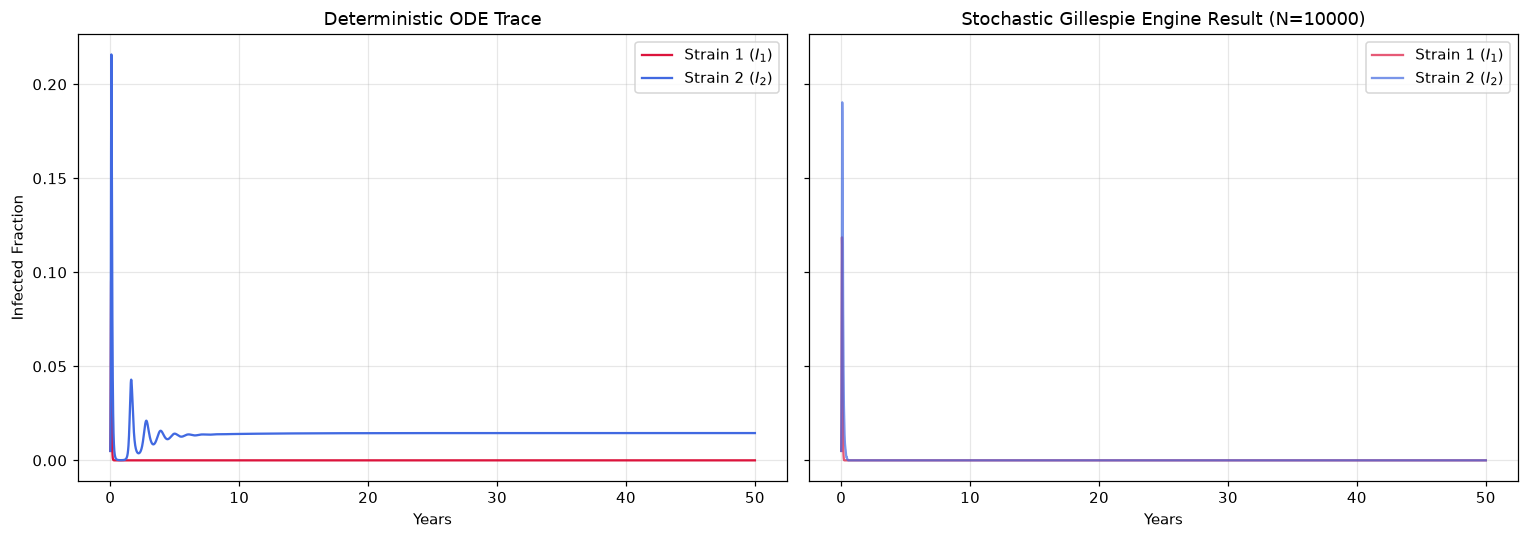

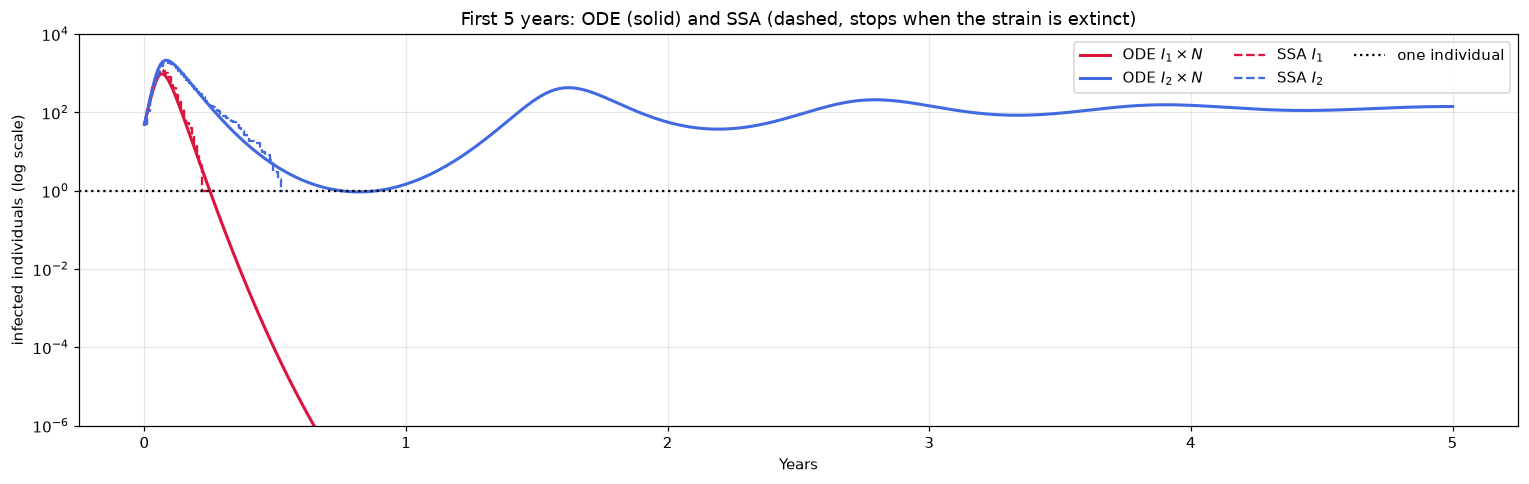

In [7]:
t0 = time.time()
t_stoch, states_stoch, ext_main = ssa_two_strain_fast(N, y0_stoch, t_max, *pars, rng=np.random.default_rng(2026))
print(f"50 years simulated in {time.time()-t0:.0f} s; extinction times in years (strain 1, strain 2):", np.round(ext_main, 3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
ax1.plot(sol_ode.t, sol_ode.y[1], color="crimson", label="Strain 1 ($I_1$)")
ax1.plot(sol_ode.t, sol_ode.y[2], color="royalblue", label="Strain 2 ($I_2$)")
ax1.set_title("Deterministic ODE Trace"); ax1.set_xlabel("Years"); ax1.set_ylabel("Infected Fraction"); ax1.legend()
ax2.plot(t_stoch, states_stoch[:, 1]/N, color="crimson", alpha=0.7, label="Strain 1 ($I_1$)")
ax2.plot(t_stoch, states_stoch[:, 2]/N, color="royalblue", alpha=0.7, label="Strain 2 ($I_2$)")
ax2.set_title(f"Stochastic Gillespie Engine Result (N={N})"); ax2.set_xlabel("Years"); ax2.legend()
plt.tight_layout(); plt.show()

# the first 5 years, in number of individuals and on a log scale: this is where everything happens
fig, ax = plt.subplots(figsize=(14, 4.5))
m5 = sol_ode.t <= 5; s5 = t_stoch <= 5
ax.semilogy(sol_ode.t[m5], sol_ode.y[1][m5]*N, "crimson", lw=2, label=r"ODE $I_1\times N$")
ax.semilogy(sol_ode.t[m5], sol_ode.y[2][m5]*N, "royalblue", lw=2, label=r"ODE $I_2\times N$")
ax.step(t_stoch[s5], np.where(states_stoch[s5, 1] > 0, states_stoch[s5, 1], np.nan), "crimson", where="post", ls="--", label="SSA $I_1$")
ax.step(t_stoch[s5], np.where(states_stoch[s5, 2] > 0, states_stoch[s5, 2], np.nan), "royalblue", where="post", ls="--", label="SSA $I_2$")
ax.axhline(1, color="k", ls=":", label="one individual"); ax.set_ylim(1e-6, 1e4)
ax.set(xlabel="Years", ylabel="infected individuals (log scale)", title="First 5 years: ODE (solid) and SSA (dashed, stops when the strain is extinct)")
ax.legend(ncol=3); plt.tight_layout(); plt.show()

In [8]:
# Population size in the SSA (births and deaths are independent events, so it fluctuates)
tot = states_stoch.sum(axis=1)
print(f"SSA total population: mean {tot.mean():.0f}, min {tot.min()}, max {tot.max()}  (target N = {N})")
print(f"SSA final state at t = 50 [S, I1, I2, R1, R2] = {states_stoch[-1]}")
print(f"ODE final state x N                        = {np.round(sol_ode.y[:, -1]*N, 1)}")

SSA total population: mean 10019, min 9937, max 10146  (target N = 10000)
SSA final state at t = 50 [S, I1, I2, R1, R2] = [9956    0    0    0    0]
ODE final state x N                        = [2.6020e+03 0.0000e+00 1.4510e+02 1.0000e-01 7.2529e+03]


## D. Investigation 4: comparative analysis

### D1. Basic reproduction numbers
With a fully susceptible population ($S\approx1$) and vital dynamics, from (2.2) a strain $i$ case infects $\beta_i$ people per year for a mean time $1/(\gamma_i+\mu)$:
$$\mathcal R_0^{i}=\frac{\beta_i}{\gamma_i+\mu}.$$

In [9]:
R0_1 = beta1 / (gamma1 + mu)
R0_2 = beta2 / (gamma2 + mu)
print(f"R0^1 = {beta1}/({gamma1}+{mu}) = {R0_1:.3f}")
print(f"R0^2 = {beta2}/({gamma2}+{mu}) = {R0_2:.3f}")

R0^1 = 120.0/(52.0+0.02) = 2.307
R0^2 = 100.0/(26.0+0.02) = 3.843


### D2. Does the ODE settle to coexistence or to cycles?

**No coexistence equilibrium.** At an equilibrium with both $I_1>0$ and $I_2>0$, equations (2.2) and (2.3) equal to zero give
$$\beta_1S^*-(\gamma_1+\mu)=0\ \Rightarrow\ S^*=\frac{1}{\mathcal R_0^1},\qquad \beta_2S^*-(\gamma_2+\mu)=0\ \Rightarrow\ S^*=\frac{1}{\mathcal R_0^2}.$$
Both hold only if $\mathcal R_0^1=\mathcal R_0^2$. Here $\mathcal R_0^1\neq\mathcal R_0^2$, so **the two strains cannot coexist at equilibrium**.

**Single strain equilibria.** With only strain $i$: $S^*=1/\mathcal R_0^i$, (2.4) or (2.5) gives $R_i^*=\dfrac{\gamma_i}{\omega_i+\mu}I_i^*$, and $S^*+I_i^*+R_i^*=1$ gives
$$I_i^*=\frac{1-1/\mathcal R_0^i}{1+\gamma_i/(\omega_i+\mu)}.$$

**Who wins? Invasion.** A rare strain $j$ entering a population where strain $i$ is at equilibrium grows if $\beta_jS^*>\gamma_j+\mu$, that is if
$$\mathcal R_{\rm inv}^{\,j\ \text{into}\ i}=\mathcal R_0^{\,j}\,S^*=\frac{\mathcal R_0^{\,j}}{\mathcal R_0^{\,i}}>1.$$
So the strain with the larger $\mathcal R_0$ can always invade, and the other cannot: **competitive exclusion**, the strain with the larger $\mathcal R_0$ wins.

The cell below computes these equilibria, checks their stability with the Jacobian of the four dimensional system of section B, and compares with the ODE at $t=50$.

In [10]:
def single_strain_eq(R0, g, w):
    S_ = 1/R0; I_ = (1 - S_) / (1 + g/(w + mu)); return S_, I_, g*I_/(w + mu)

S1s, I1s, R1s = single_strain_eq(R0_1, gamma1, omega1)
S2s, I2s, R2s = single_strain_eq(R0_2, gamma2, omega2)
print(f"strain 1 alone: S*={S1s:.5f}  I1*={I1s:.5f}  R1*={R1s:.5f}")
print(f"strain 2 alone: S*={S2s:.5f}  I2*={I2s:.5f}  R2*={R2s:.5f}")
print(f"ODE at t = 50 : S={sol_ode.y[0,-1]:.5f}  I1={sol_ode.y[1,-1]:.1e}  I2={sol_ode.y[2,-1]:.5f}  R1={sol_ode.y[3,-1]:.1e}  R2={sol_ode.y[4,-1]:.5f}")

print(f"\nstrain 2 invading strain 1: R_inv = R0^2/R0^1 = {R0_2/R0_1:.3f}  (> 1: invades)")
print(f"strain 1 invading strain 2: R_inv = R0^1/R0^2 = {R0_1/R0_2:.3f}  (< 1: cannot invade)")

# Jacobian of the reduced 4D system (variables I1, I2, R1, R2), section B
v = sp.Matrix([I1, I2, R1, R2]); Ssym = 1 - I1 - I2 - R1 - R2
f4 = sp.Matrix([b1*Ssym*I1 - (g1+m)*I1, b2*Ssym*I2 - (g2+m)*I2, g1*I1 - (w1+m)*R1, g2*I2 - (w2+m)*R2])
Jf = sp.lambdify([v, (m, b1, g1, w1, b2, g2, w2)], f4.jacobian(v), "numpy")
for label, point in [("disease free      ", [0, 0, 0, 0]),
                     ("strain 1 alone    ", [I1s, 0, R1s, 0]),
                     ("strain 2 alone    ", [0, I2s, 0, R2s])]:
    ev = np.linalg.eigvals(np.array(Jf(point, pars), dtype=float))
    print(f"{label}: eigenvalues {np.round(np.sort_complex(ev), 3)}  ->  {'stable' if ev.real.max() < 0 else 'unstable'}")

ev2 = np.linalg.eigvals(np.array(Jf([0, I2s, 0, R2s], pars), dtype=float)); lam = ev2[np.argmax(ev2.imag)]
print(f"\napproach to the strain 2 equilibrium: damped oscillation, period {2*np.pi/lam.imag:.2f} years, "
      f"amplitude halves every {np.log(2)/(-lam.real):.2f} years")

strain 1 alone: S*=0.43350  I1*=0.00239  R1*=0.56411
strain 2 alone: S*=0.26020  I2*=0.01451  R2*=0.72529
ODE at t = 50 : S=0.26020  I1=7.1e-136  I2=0.01451  R1=6.2e-06  R2=0.72529

strain 2 invading strain 1: R_inv = R0^2/R0^1 = 1.666  (> 1: invades)
strain 1 invading strain 2: R_inv = R0^1/R0^2 = 0.600  (< 1: cannot invade)
disease free      : eigenvalues [-0.52+0.j -0.22+0.j 67.98+0.j 73.98+0.j]  ->  unstable
strain 1 alone    : eigenvalues [-0.52 +0.j    -0.253-3.859j -0.253+3.859j 17.33 +0.j   ]  ->  unstable
strain 2 alone    : eigenvalues [-20.796+0.j     -0.985-6.124j  -0.985+6.124j  -0.22 +0.j   ]  ->  stable

approach to the strain 2 equilibrium: damped oscillation, period 1.03 years, amplitude halves every 0.70 years


### D3. The ODE keeps tiny values alive; the SSA cannot

In the ODE an infected fraction is a continuous number. It can become $10^{-6}$, $10^{-40}$, or smaller, and still be positive, so a strain "survives" and may rebound later. In the SSA the infected count is a whole number, and **0 is absorbing**: there is no immigration, and the only events that create an $I_i$ (event 6 or 7) have propensity proportional to $I_i$. Once $I_i=0$ the strain is gone for ever.

With equations (2.1) to (2.5) the ODE shows this twice in the first years:
* strain 1 is excluded: its fraction falls far below one individual and never comes back;
* strain 2 makes a large first epidemic that uses up the susceptibles, then **crashes to a tiny value before rebounding** to its endemic level when new susceptibles have accumulated (births and waning). This is the "tiny value, but alive, then rebounds" situation of the sheet.

ODE strain 2: peak 0.217 at t=0.08 y; minimum after the peak 9.35e-05 at t=0.82 y = 0.93 individuals when N = 10000; back to 0.0142 (142 individuals) by t = 5 y
ODE strain 1 at t = 1, 2, 5 years (individuals when N = 10,000): ['6.8e-10', '5.0e-17', '3.2e-42']



SSA, 40 runs of 5 years: strain 1 extinct in 100% (median time 0.25 y), strain 2 extinct in 85% (median time 0.57 y)
runs in which strain 2 is still present at t = 5 y: 6 of 40; ODE says 142 infected individuals


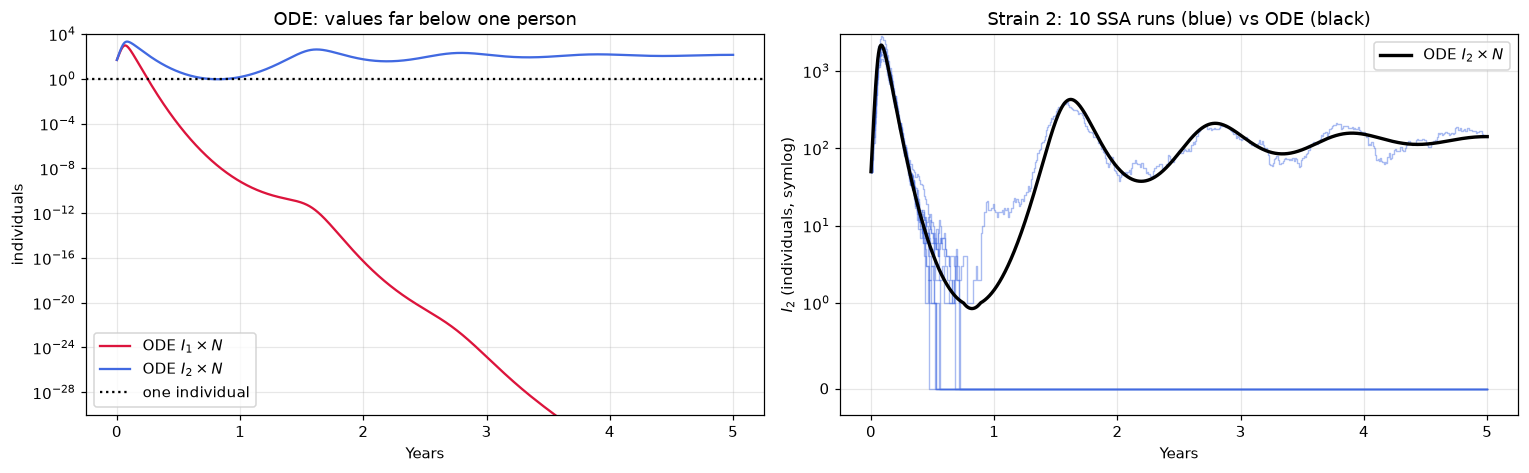

In [11]:
sol5 = solve_model(waning_two_strain_sir, y0_ode, 5, n=5001)
i_pk = np.argmax(sol5.y[2]); i_min = i_pk + np.argmin(sol5.y[2][i_pk:i_pk + 3000])
print(f"ODE strain 2: peak {sol5.y[2][i_pk]:.3f} at t={sol5.t[i_pk]:.2f} y; "
      f"minimum after the peak {sol5.y[2][i_min]:.2e} at t={sol5.t[i_min]:.2f} y "
      f"= {sol5.y[2][i_min]*N:.2f} individuals when N = {N}; back to {sol5.y[2][-1]:.4f} ({sol5.y[2][-1]*N:.0f} individuals) by t = 5 y")
print("ODE strain 1 at t = 1, 2, 5 years (individuals when N = 10,000):", [f"{sol5.y[1][int(t*1000)]*N:.1e}" for t in (1, 2, 5)])
I2_min_frac = sol5.y[2][i_min]

# 40 SSA runs at N = 10,000
rng = np.random.default_rng(5)
runs = [ssa_two_strain_fast(N, y0_stoch, 5, *pars, dt=0.01, rng=rng) for _ in range(40)]
ep = np.array([r[2] for r in runs])
print(f"\nSSA, 40 runs of 5 years: strain 1 extinct in {np.mean(~np.isnan(ep[:,0])):.0%} (median time {np.nanmedian(ep[:,0]):.2f} y), "
      f"strain 2 extinct in {np.mean(~np.isnan(ep[:,1])):.0%} (median time {np.nanmedian(ep[:,1]):.2f} y)")
print("runs in which strain 2 is still present at t = 5 y:", int(sum(r[1][-1, 2] > 0 for r in runs)), "of 40;",
      "ODE says", round(sol5.y[2][-1]*N), "infected individuals")

fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))
axs[0].semilogy(sol5.t, np.maximum(sol5.y[1]*N, 1e-40), "crimson", label=r"ODE $I_1\times N$")
axs[0].semilogy(sol5.t, np.maximum(sol5.y[2]*N, 1e-40), "royalblue", label=r"ODE $I_2\times N$")
axs[0].axhline(1, color="k", ls=":", label="one individual"); axs[0].set_ylim(1e-30, 1e4)
axs[0].set(xlabel="Years", ylabel="individuals", title="ODE: values far below one person"); axs[0].legend()
for gg, oo, _ in runs[:10]:
    axs[1].step(gg, oo[:, 2], where="post", color="royalblue", alpha=0.45, lw=0.9)
axs[1].plot(sol5.t, sol5.y[2]*N, "k", lw=2.2, label=r"ODE $I_2\times N$")
axs[1].set_yscale("symlog", linthresh=1); axs[1].set_ylim(-0.3, 3e3)
axs[1].set(xlabel="Years", ylabel="$I_2$ (individuals, symlog)", title="Strain 2: 10 SSA runs (blue) vs ODE (black)"); axs[1].legend()
plt.tight_layout(); plt.show()

### D4. How large must the population be for strain 2 to survive the crash?

The ODE minimum of strain 2 is a fraction; in a population of size $N$ it corresponds to $N\times(\text{minimum})$ individuals. If that number is of order 1, the SSA will usually hit 0. For each $N$ we run the SSA for 3 years (the crash of strain 2 is over by about year 1.5, and the ODE has rebounded by year 3) (starting with $0.5\%$ of the population infected with each strain) and record whether each strain goes extinct.

In [12]:
def ext_ensemble(N, n_runs, seed, t_end=3.0):
    rng = np.random.default_rng(seed)
    i0 = max(1, int(round(0.005*N)))
    y0 = [N - 2*i0, i0, i0, 0, 0]
    return np.array([ssa_two_strain_fast(N, y0, t_end, *pars, dt=0.5, rng=rng, stop_when_extinct=True)[2] for _ in range(n_runs)])

t0 = time.time()
N_runs = {1_000: 40, 10_000: 40, 100_000: 40, 300_000: 20}
ext_res = {Nn: ext_ensemble(Nn, nr, seed=Nn) for Nn, nr in N_runs.items()}
print(f"done in {time.time()-t0:.0f} s")

rows = []
for Nn, e in ext_res.items():
    rows.append({"N": Nn, "runs": len(e),
                 "ODE minimum of I2 (individuals)": round(I2_min_frac*Nn, 2),
                 "P(strain 1 extinct)": np.mean(~np.isnan(e[:, 0])),
                 "median year strain 1 lost": np.nanmedian(e[:, 0]) if np.any(~np.isnan(e[:, 0])) else np.nan,
                 "P(strain 2 extinct)": np.mean(~np.isnan(e[:, 1])),
                 "median year strain 2 lost": np.nanmedian(e[:, 1]) if np.any(~np.isnan(e[:, 1])) else np.nan,
                 "P(both extinct)": np.mean(~np.isnan(e[:, 0]) & ~np.isnan(e[:, 1]))})
df_ext = pd.DataFrame(rows).round(3)
df_ext

done in 88 s


,N,runs,ODE minimum of I2 (individuals),P(strain 1 extinct),median year strain 1 lost,P(strain 2 extinct),median year strain 2 lost,P(both extinct)
0,1000,40,0.09,1.0,0.197,1.000,0.396,1.000
1,10000,40,0.93,1.0,0.246,0.925,0.591,0.925
2,100000,40,9.35,1.0,0.309,0.525,0.932,0.525
3,300000,20,28.05,1.0,0.325,0.050,1.128,0.050


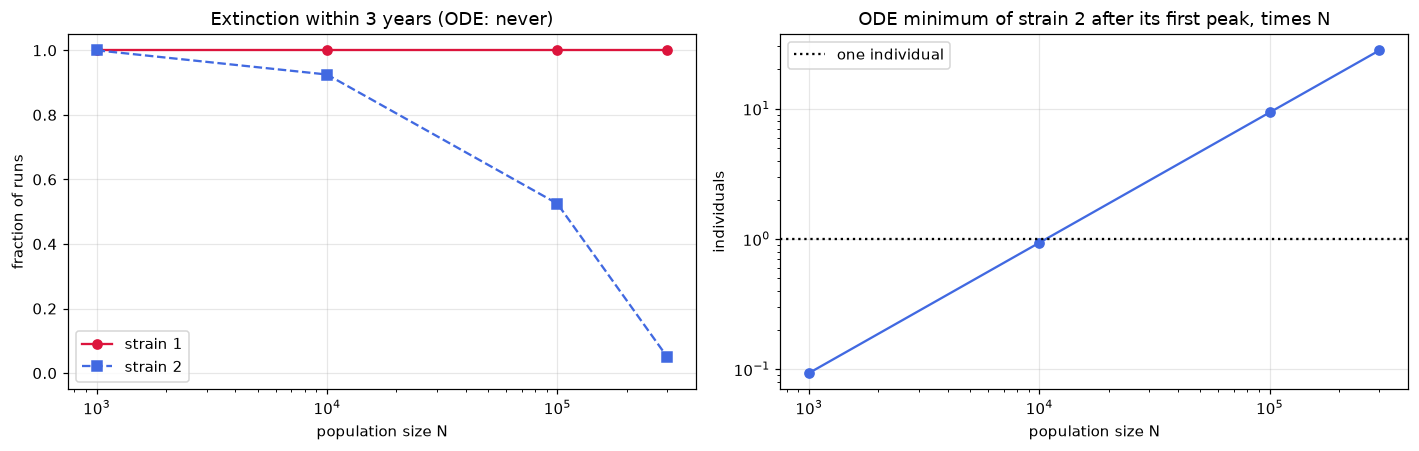

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
Nn_arr = np.array(list(N_runs))
axs[0].semilogx(Nn_arr, df_ext["P(strain 1 extinct)"], "o-", color="crimson", label="strain 1")
axs[0].semilogx(Nn_arr, df_ext["P(strain 2 extinct)"], "s--", color="royalblue", label="strain 2")
axs[0].set(xlabel="population size N", ylabel="fraction of runs", title="Extinction within 3 years (ODE: never)", ylim=(-0.05, 1.05)); axs[0].legend()
axs[1].loglog(Nn_arr, I2_min_frac*Nn_arr, "o-", color="royalblue")
axs[1].axhline(1, color="k", ls=":", label="one individual")
axs[1].set(xlabel="population size N", ylabel="individuals", title="ODE minimum of strain 2 after its first peak, times N"); axs[1].legend()
plt.tight_layout(); plt.show()

## Summary of the answers (Part 2)

*All results use equations (2.1) to (2.5) as printed in the sheet. Every number below comes from the cells above (fixed random seeds). If you change a seed or a setting, re-check them before quoting.*

**Investigation 1 (cartoon).** See section A. Each strain has its loop $S\to I_i\to R_i\to S$ (infection, recovery, waning). There are births into $S$ and deaths from every class. The two strains interact only through $S$: they compete for the same susceptible people.

**Investigation 2 (reduction).** Adding (2.1) to (2.5), all transfer terms cancel. This leaves $\frac{d}{dt}(S+I_1+I_2+R_1+R_2)=\mu\,[1-(S+I_1+I_2+R_1+R_2)]$, which is 0 because the fractions start with sum 1. So $S=1-I_1-I_2-R_1-R_2$ for all time, and substituting gives the four equations boxed in section B:
$$\dot I_i=\beta_i(1-I_1-I_2-R_1-R_2)I_i-(\gamma_i+\mu)I_i,\qquad \dot R_i=\gamma_iI_i-(\omega_i+\mu)R_i\quad(i=1,2).$$
The sympy cell confirms the three steps.

**Investigation 3 (code and plot).** The propensities are in the table of section A and in `gillespie_two_strain`. The sheet's function and the fast version agree with each other and with the ODE during the first epidemic wave (table in section C, $t=0.1$ year). The side by side plot is in section C.

### Investigation 4

**1. Steady coexistence or oscillations?** *Neither: competitive exclusion, then a damped oscillation to a single strain equilibrium.*
* $\mathcal R_0^1=120/52.02=2.31$ and $\mathcal R_0^2=100/26.02=3.84$. Both exceed 1, so each strain alone can spread.
* There is **no coexistence equilibrium**. Equations (2.2) and (2.3) would need $S^*=1/\mathcal R_0^1$ and $S^*=1/\mathcal R_0^2$ at the same time, which is impossible since $\mathcal R_0^1\neq\mathcal R_0^2$.
* Strain 2, with the larger $\mathcal R_0$, wins. It can invade strain 1 ($\mathcal R_0^2/\mathcal R_0^1=1.67>1$), but strain 1 cannot invade strain 2 ($\mathcal R_0^1/\mathcal R_0^2=0.60<1$). The Jacobian confirms this: the strain 2 equilibrium is stable and the strain 1 equilibrium is unstable.
* The ODE goes to $S^*=0.260$, $I_2^*=0.0145$, $R_2^*=0.725$, with $I_1\to0$ ($10^{-135}$ at year 50).
* The approach is a **damped oscillation**, not a sustained cycle. The eigenvalues $-0.99\pm6.12i$ give a period of about 1 year, and the amplitude halves every 0.7 year.

**2. Stochastic extinction versus deterministic permanence.**
* **The ODE keeps tiny values alive.** Strain 2 peaks at $I_2=0.217$ (month 1), uses up the susceptibles, and falls to $9.4\times10^{-5}$ at $t=0.82$ year. That is **0.93 individual** when $N=10{,}000$. It then rebounds to 142 individuals by year 5, because births and waning refill $S$. Strain 1 falls to $7\times10^{-10}$ individuals by year 1, then to $10^{-42}$ by year 5. These are mathematically positive but physically meaningless numbers.
* **The SSA cannot do this.** A count of 0 is absorbing: the infection events of strain $i$ have propensity proportional to $I_i$, and there is no immigration. A strain that hits 0 never returns, even if the ODE says it should rebound.
* **At $N=10{,}000$:** strain 1 is lost in 100% of 40 runs (median 0.25 year). Strain 2 is lost in 85% of runs (median 0.57 year), during the crash that the ODE survives. In the run plotted in section C both strains are gone by year 0.53, and the population ends with nobody infected. The ODE, by contrast, predicts 145 infected people for ever.
* **Effect of population size** (section D4, 3 years). Strain 2 survives the crash only when the ODE minimum is many individuals:

| $N$ | ODE minimum of $I_2$ (individuals) | strain 2 lost |
|---|---|---|
| 1,000 | 0.09 | 100% |
| 10,000 | 0.93 | 92.5% |
| 100,000 | 9.4 | 52.5% |
| 300,000 | 28 | 5% |

  Strain 1 is lost in 100% of runs at every $N$, as the ODE predicts (exclusion). With 40 runs per value, the 85% and 92.5% at $N=10{,}000$ agree within sampling noise.

**3. Does the SSA at $N=10{,}000$ agree with the ODE?** Only during the first epidemic wave (first month), where the means agree closely. After the wave they disagree completely. The ODE predicts strain 2 endemic at 145 infected people. The SSA usually loses both strains in the first year, because the ODE trough of strain 2 is below one person. The SSA total population stayed between 9,937 and 10,146, because births and deaths are separate random events.

**Take home message.** With equations (2.1) to (2.5), the deterministic model predicts that strain 2 excludes strain 1 and settles, after damped oscillations, at an endemic level. But on the way it passes through a trough where the ODE value is below one person. The stochastic model turns that trough into real extinction unless the population is very large (hundreds of thousands here). The ODE's "tiny but positive, then rebounds" behaviour is not a real outcome when individuals are discrete.